In [1]:
import pandas as pd

produksi_path = "Produksi_Padi_Bulanan_2000-2024.csv"
produksi_df = pd.read_csv(produksi_path)

print("=== Preview: Produksi Padi Bulanan (2000–2024) ===")
print(produksi_df.head())
print("\nInfo Produksi:")
print(produksi_df.info())

iklim_path = "Dataset_Iklim_Bulanan_2000-2024.csv"
iklim_df = pd.read_csv(iklim_path)

print("\n=== Preview: Dataset Iklim Bulanan (2000–2024) ===")
print(iklim_df.head())
print("\nInfo Iklim:")
print(iklim_df.info())

=== Preview: Produksi Padi Bulanan (2000–2024) ===
   Tahun     Bulan  Produksi
0   2000   Januari     6.212
1   2000  Februari     5.341
2   2000     Maret     6.432
3   2000     April     6.013
4   2000       Mei     4.445

Info Produksi:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Tahun     300 non-null    int64  
 1   Bulan     300 non-null    object 
 2   Produksi  300 non-null    float64
dtypes: float64(1), int64(1), object(1)
memory usage: 7.2+ KB
None

=== Preview: Dataset Iklim Bulanan (2000–2024) ===
   Tahun     Bulan  Suhu (°C)  Curah Hujan (mm)
0   2000   Januari      27.39             213.5
1   2000  Februari      25.77             246.1
2   2000     Maret      25.62             403.0
3   2000     April      28.23             177.7
4   2000       Mei      27.87             239.0

Info Iklim:
<class 'pandas.core.frame.DataFrame'>
Ra

In [2]:
# === 2.1 Gabungkan data produksi dan iklim berdasarkan Tahun & Bulan ===
data_merged = pd.merge(produksi_df, iklim_df, on=["Tahun", "Bulan"], how="inner")

print("=== Data Gabungan Produksi + Iklim ===")
print(data_merged.head())

# === 2.2 Cek jumlah data dan kolom ===
print("\nInfo Data Gabungan:")
print(data_merged.info())

# === 2.3 Cek nilai kosong (jika ada) ===
print("\nJumlah Nilai Kosong per Kolom:")
print(data_merged.isnull().sum())

# === 2.4 Jika ada nilai kosong, isi dengan metode forward fill (opsional) ===
data_merged = data_merged.fillna(method='ffill')

# === 2.5 Simpan hasil gabungan untuk referensi (opsional) ===
data_merged.to_csv("Data_Gabungan_Produksi_Iklim_Bulanan.csv", index=False)
print("\n✅ Data gabungan berhasil dibuat dan disimpan sebagai 'Data_Gabungan_Produksi_Iklim_Bulanan.csv'")


=== Data Gabungan Produksi + Iklim ===
   Tahun     Bulan  Produksi  Suhu (°C)  Curah Hujan (mm)
0   2000   Januari     6.212      27.39             213.5
1   2000  Februari     5.341      25.77             246.1
2   2000     Maret     6.432      25.62             403.0
3   2000     April     6.013      28.23             177.7
4   2000       Mei     4.445      27.87             239.0

Info Data Gabungan:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Tahun             300 non-null    int64  
 1   Bulan             300 non-null    object 
 2   Produksi          300 non-null    float64
 3   Suhu (°C)         300 non-null    float64
 4   Curah Hujan (mm)  300 non-null    float64
dtypes: float64(3), int64(1), object(1)
memory usage: 11.8+ KB
None

Jumlah Nilai Kosong per Kolom:
Tahun               0
Bulan               0
Produksi       

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12936\2978785683.py:16: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data_merged = data_merged.fillna(method='ffill')


In [3]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# === 3.1 Hapus kolom non-numerik (Tahun, Bulan) sebelum scaling ===
features = data_merged.drop(columns=["Tahun", "Bulan"])

# === 3.2 Normalisasi ke rentang [0, 1] ===
scaler = MinMaxScaler()
scaled_features = scaler.fit_transform(features)

print("=== Data Setelah Scaling (5 baris pertama) ===")
print(scaled_features[:5])

=== Data Setelah Scaling (5 baris pertama) ===
[[0.77821164 0.68678161 0.41125978]
 [0.43811011 0.22126437 0.49356223]
 [0.86411558 0.17816092 0.88967432]
 [0.70050761 0.92816092 0.32087857]
 [0.08824678 0.82471264 0.47563747]]


In [4]:
print("\nNilai minimum tiap kolom:", scaler.data_min_)
print("Nilai maksimum tiap kolom:", scaler.data_max_)


Nilai minimum tiap kolom: [ 4.219 25.    50.6  ]
Nilai maksimum tiap kolom: [  6.78  28.48 446.7 ]


In [5]:
# === 3.3 Fungsi untuk membuat data sekuensial (X, y) ===
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:i+seq_length]
        y = data[i+seq_length, 0]   # kolom ke-0 = produksi padi
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 4
X, y = create_sequences(scaled_features, seq_length)

print(f"\nUkuran X (input sequences): {X.shape}")
print(f"Ukuran y (target): {y.shape}")


Ukuran X (input sequences): (296, 4, 3)
Ukuran y (target): (296,)


In [6]:
# === 3.5 Konversi ke tensor PyTorch ===
import torch
X = torch.from_numpy(X).float()
y = torch.from_numpy(y).float().view(-1, 1)

print("\nContoh satu input sequence:")
print(X[0])
print("\nContoh target untuk sequence tersebut:")
print(y[0])



Contoh satu input sequence:
tensor([[0.7782, 0.6868, 0.4113],
        [0.4381, 0.2213, 0.4936],
        [0.8641, 0.1782, 0.8897],
        [0.7005, 0.9282, 0.3209]])

Contoh target untuk sequence tersebut:
tensor([0.0882])


In [7]:
import torch
import torch.nn as nn

# === 4.1 Tentukan jumlah fitur input dari data X ===
input_size = X.shape[2]

# === 4.2 Definisi model LSTM ===
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2):
        super(LSTMModel, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)


    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :])
        return out

# === 4.3 Definisi model GRU ===
class GRUModel(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2):
        super(GRUModel, self).__init__()
        self.gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)


    def forward(self, x):
        out, _ = self.gru(x)
        out = self.fc(out[:, -1, :])
        return out

# === 4.4 Definisi model BiLSTM ===
class BiLSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2):
        super(BiLSTMModel, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers,
                            batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_size * 2, 1)


    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :])
        return out
    
# === 4B.1 Bagi data menjadi train dan test ===
train_size = int(len(X) * 0.8)  # 60% training, 40% testing


X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]


print(f"Total data: {len(X)}")
print(f"Data train: {len(X_train)}")
print(f"Data test : {len(X_test)}")

# === 4B.2 Fungsi pelatihan model diperbarui untuk menerima data train/test ===
def train_model(model, X_train, y_train, X_test, y_test, epochs=300, lr=0.01, name="Model"):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
   
    for epoch in range(epochs):
        model.train()
        output = model(X_train)
        loss = criterion(output, y_train)


        optimizer.zero_grad()
        loss.backward()
        optimizer.step()


        if (epoch + 1) % 50 == 0:
            model.eval()
            with torch.no_grad():
                test_pred = model(X_test)
                test_loss = criterion(test_pred, y_test)
            print(f"[{name}] Epoch {epoch+1}/{epochs}, Train Loss: {loss.item():.6f}, Test Loss: {test_loss.item():.6f}")
   
    return model

# === 4B.3 Latih ketiga model dengan pembagian data ===
print("\n=== Mulai Training Model (Dengan Data Uji) ===\n")


print("\n=== Training Model LSTM ===\n")

lstm_model = train_model(
    LSTMModel(input_size),
    X_train,
    y_train,
    X_test,
    y_test,
    name="LSTM"
)

print("\n✅ Semua model selesai dilatih dengan pembagian train/test!")


Total data: 296
Data train: 236
Data test : 60

=== Mulai Training Model (Dengan Data Uji) ===


=== Training Model LSTM ===

[LSTM] Epoch 50/300, Train Loss: 0.083143, Test Loss: 0.094334
[LSTM] Epoch 100/300, Train Loss: 0.073581, Test Loss: 0.100393
[LSTM] Epoch 150/300, Train Loss: 0.058897, Test Loss: 0.135591
[LSTM] Epoch 200/300, Train Loss: 0.015987, Test Loss: 0.205114
[LSTM] Epoch 250/300, Train Loss: 0.001699, Test Loss: 0.210748
[LSTM] Epoch 300/300, Train Loss: 0.000123, Test Loss: 0.222625

✅ Semua model selesai dilatih dengan pembagian train/test!


In [8]:
print("\n=== Training Model GRU ===\n")

gru_model = train_model(
    GRUModel(input_size),
    X_train,
    y_train,
    X_test,
    y_test,
    name="GRU"
)


=== Training Model GRU ===

[GRU] Epoch 50/300, Train Loss: 0.081879, Test Loss: 0.096877
[GRU] Epoch 100/300, Train Loss: 0.079099, Test Loss: 0.106906
[GRU] Epoch 150/300, Train Loss: 0.070663, Test Loss: 0.105333
[GRU] Epoch 200/300, Train Loss: 0.048648, Test Loss: 0.162169
[GRU] Epoch 250/300, Train Loss: 0.072131, Test Loss: 0.283831
[GRU] Epoch 300/300, Train Loss: 0.003676, Test Loss: 0.241533


In [9]:
print("\n=== Training Model BiLSTM ===\n")

bilstm_model = train_model(
    BiLSTMModel(input_size),
    X_train,
    y_train,
    X_test,
    y_test,
    name="BiLSTM"
)


=== Training Model BiLSTM ===

[BiLSTM] Epoch 50/300, Train Loss: 0.082897, Test Loss: 0.096502
[BiLSTM] Epoch 100/300, Train Loss: 0.077696, Test Loss: 0.106522
[BiLSTM] Epoch 150/300, Train Loss: 0.067003, Test Loss: 0.135734
[BiLSTM] Epoch 200/300, Train Loss: 0.050378, Test Loss: 0.161399
[BiLSTM] Epoch 250/300, Train Loss: 0.019358, Test Loss: 0.173926
[BiLSTM] Epoch 300/300, Train Loss: 0.002488, Test Loss: 0.165171


In [10]:
import numpy as np
# === 6.1 Fungsi evaluasi regresi ===
def evaluate_regression(model, X_test, y_test, name="Model"):
    model.eval()
    with torch.no_grad():
        preds = model(X_test).numpy().flatten()
        actuals = y_test.numpy().flatten()
    # Error
    mae = np.mean(np.abs(preds - actuals))
    rmse = np.sqrt(np.mean((preds - actuals) ** 2))
    # Akurasi berbasis toleransi

    print(f"\n[{name}] Evaluation Result")
    print(f"MAE   : {mae:.3f}")
    print(f"RMSE  : {rmse:.3f}")

    return mae, rmse

In [15]:
import numpy as np
from sklearn.metrics import r2_score

# === 6.1 Fungsi evaluasi regresi ===
def evaluate_regression(model, X_test, y_test, name="Model"):
    model.eval()
    with torch.no_grad():
        preds = model(X_test).numpy().flatten()
        actuals = y_test.numpy().flatten()

    # Error
    mae = np.mean(np.abs(preds - actuals))
    rmse = np.sqrt(np.mean((preds - actuals) ** 2))

    # ✅ Tambahan R2
    r2 = r2_score(actuals, preds)

    print(f"\n[{name}] Evaluation Result")
    print(f"MAE   : {mae:.3f}")
    print(f"RMSE  : {rmse:.3f}")
    print(f"R2    : {r2:.3f}")

    return mae, rmse, r2

In [11]:
print("\n=== Evaluasi Model ===")

lstm_acc = evaluate_regression(
    lstm_model, X_test, y_test, name="LSTM"
)

gru_acc = evaluate_regression(
    gru_model, X_test, y_test, name="GRU"
)

bilstm_acc = evaluate_regression(
    bilstm_model, X_test, y_test, name="BiLSTM"
)



=== Evaluasi Model ===

[LSTM] Evaluation Result
MAE   : 0.362
RMSE  : 0.472

[GRU] Evaluation Result
MAE   : 0.376
RMSE  : 0.491

[BiLSTM] Evaluation Result
MAE   : 0.317
RMSE  : 0.406


In [16]:
print("\n=== Evaluasi Model ===")

mae_lstm, rmse_lstm, r2_lstm = evaluate_regression(
    lstm_model, X_test, y_test, name="LSTM"
)

mae_gru, rmse_gru, r2_gru = evaluate_regression(
    gru_model, X_test, y_test, name="GRU"
)

mae_bilstm, rmse_bilstm, r2_bilstm = evaluate_regression(
    bilstm_model, X_test, y_test, name="BiLSTM"
)


=== Evaluasi Model ===

[LSTM] Evaluation Result
MAE   : 0.362
RMSE  : 0.472
R2    : -1.385

[GRU] Evaluation Result
MAE   : 0.376
RMSE  : 0.491
R2    : -1.587

[BiLSTM] Evaluation Result
MAE   : 0.317
RMSE  : 0.406
R2    : -0.769


In [17]:
actuals_train = y_train.numpy().flatten()

# === Ambil hasil prediksi data latih ===
with torch.no_grad():
    lstm_train_pred = lstm_model(X_train).numpy().flatten()
    gru_train_pred = gru_model(X_train).numpy().flatten()
    bilstm_train_pred = bilstm_model(X_train).numpy().flatten()

# === Buat DataFrame hasil prediksi data latih ===
n_train = len(actuals_train)

tahun_bulan_train = data_merged[["Tahun", "Bulan"]].values[:n_train]

results_train = pd.DataFrame({
    "Tahun": tahun_bulan_train[:, 0],
    "Bulan": tahun_bulan_train[:, 1],
    "Aktual": actuals_train,
    "LSTM": lstm_train_pred,
    "GRU": gru_train_pred,
    "BiLSTM": bilstm_train_pred
})

print("\n=== Hasil Prediksi (Data Latih) ===")
print(results_train.round(3).tail(12))


=== Hasil Prediksi (Data Latih) ===
    Tahun      Bulan  Aktual   LSTM    GRU  BiLSTM
224  2018  September   0.636  0.624  0.597   0.580
225  2018    Oktober   0.100  0.100  0.084   0.114
226  2018   November   0.135  0.129  0.104   0.153
227  2018   Desember   0.418  0.430  0.437   0.431
228  2019    Januari   0.973  0.974  0.990   1.018
229  2019   Februari   0.598  0.600  0.617   0.590
230  2019      Maret   0.940  0.943  0.924   0.960
231  2019      April   0.809  0.816  0.804   0.770
232  2019        Mei   0.467  0.466  0.498   0.561
233  2019       Juni   0.789  0.766  0.799   0.808
234  2019       Juli   0.011 -0.006 -0.010  -0.009
235  2019    Agustus   0.103  0.087  0.089   0.132


In [18]:
actuals = y_test.numpy().flatten()

# === 5.3 Ambil hasil prediksi data uji ===
with torch.no_grad():
    lstm_pred = lstm_model(X_test).numpy().flatten()
    gru_pred = gru_model(X_test).numpy().flatten()
    bilstm_pred = bilstm_model(X_test).numpy().flatten()

# === 5.3 Buat DataFrame hasil prediksi ===
n_test = len(actuals)
tahun_bulan = data_merged[["Tahun", "Bulan"]].values[-n_test:]

results = pd.DataFrame({
    "Tahun": tahun_bulan[:, 0],
    "Bulan": tahun_bulan[:, 1],
    "Aktual": actuals,
    "LSTM": lstm_pred,
    "GRU": gru_pred,
    "BiLSTM": bilstm_pred
})

print("\n=== Hasil Prediksi (Data Uji) ===")
print(results.round(3).tail(12))


=== Hasil Prediksi (Data Uji) ===
   Tahun      Bulan  Aktual   LSTM    GRU  BiLSTM
48  2024    Januari   0.524  1.022  0.479   1.003
49  2024   Februari   0.096  0.694  0.306   0.332
50  2024      Maret   0.839  0.725  0.386   0.825
51  2024      April   0.045  0.277  0.773   0.837
52  2024        Mei   0.932  0.765  0.562   0.923
53  2024       Juni   0.093  0.164  0.526   0.631
54  2024       Juli   0.849  0.733  0.506   0.589
55  2024    Agustus   0.909  0.060  0.295   0.359
56  2024  September   0.987  0.818  0.778   0.614
57  2024    Oktober   0.807  0.132  0.356   0.327
58  2024   November   0.784  0.424  0.758   0.874
59  2024   Desember   0.645  0.746  0.780   0.794


In [28]:
# Pastikan Anda sudah menginstal openpyxl jika belum:
# !pip install openpyxl

# Membuat objek ExcelWriter
with pd.ExcelWriter("Hasiltiga.xlsx") as writer:
    # Simpan Data Latih ke Sheet1
    results_train.to_excel(writer, sheet_name='Data_Latih', index=False)
    
    # Simpan Data Uji ke Sheet2
    results.to_excel(writer, sheet_name='Data_Uji', index=False)

print("✅ File 'Hasiltiga.xlsx' berhasil dibuat!")

✅ File 'Hasiltiga.xlsx' berhasil dibuat!


In [19]:
# === Ambil 12 bulan data uji (tahun 2024) ===
prediksi_2024 = results.tail(12).copy()

# === Hitung Absolute Error per model ===
prediksi_2024["Selisih_LSTM"]   = (prediksi_2024["Aktual"] - prediksi_2024["LSTM"]).abs()
prediksi_2024["Selisih_GRU"]    = (prediksi_2024["Aktual"] - prediksi_2024["GRU"]).abs()
prediksi_2024["Selisih_BiLSTM"] = (prediksi_2024["Aktual"] - prediksi_2024["BiLSTM"]).abs()

print(prediksi_2024.round(3))

   Tahun      Bulan  Aktual   LSTM    GRU  BiLSTM  Selisih_LSTM  Selisih_GRU  \
48  2024    Januari   0.524  1.022  0.479   1.003         0.498        0.045   
49  2024   Februari   0.096  0.694  0.306   0.332         0.598        0.210   
50  2024      Maret   0.839  0.725  0.386   0.825         0.114        0.453   
51  2024      April   0.045  0.277  0.773   0.837         0.232        0.727   
52  2024        Mei   0.932  0.765  0.562   0.923         0.167        0.369   
53  2024       Juni   0.093  0.164  0.526   0.631         0.071        0.433   
54  2024       Juli   0.849  0.733  0.506   0.589         0.116        0.343   
55  2024    Agustus   0.909  0.060  0.295   0.359         0.849        0.614   
56  2024  September   0.987  0.818  0.778   0.614         0.169        0.209   
57  2024    Oktober   0.807  0.132  0.356   0.327         0.674        0.451   
58  2024   November   0.784  0.424  0.758   0.874         0.360        0.026   
59  2024   Desember   0.645  0.746  0.78

In [20]:
import numpy as np

prediksi_2024['RMSE_LSTM'] = np.sqrt((prediksi_2024['Aktual'] - prediksi_2024['LSTM'])**2)
prediksi_2024['RMSE_GRU'] = np.sqrt((prediksi_2024['Aktual'] - prediksi_2024['GRU'])**2)
prediksi_2024['RMSE_BiLSTM'] = np.sqrt((prediksi_2024['Aktual'] - prediksi_2024['BiLSTM'])**2)

print(prediksi_2024)


   Tahun      Bulan    Aktual      LSTM       GRU    BiLSTM  Selisih_LSTM  \
48  2024    Januari  0.524405  1.022158  0.479208  1.002995      0.497753   
49  2024   Februari  0.095666  0.693716  0.305761  0.332085      0.598050   
50  2024      Maret  0.838735  0.724899  0.386132  0.824597      0.113836   
51  2024      April  0.045295  0.277432  0.772525  0.837416      0.232137   
52  2024        Mei  0.931667  0.764952  0.562173  0.922735      0.166715   
53  2024       Juni  0.093323  0.164205  0.526270  0.630765      0.070882   
54  2024       Juli  0.848887  0.732825  0.506174  0.588800      0.116062   
55  2024    Agustus  0.909020  0.060160  0.294598  0.359399      0.848860   
56  2024  September  0.987114  0.818065  0.778108  0.613686      0.169050   
57  2024    Oktober  0.806716  0.132488  0.355562  0.327374      0.674229   
58  2024   November  0.784069  0.423854  0.758300  0.873914      0.360215   
59  2024   Desember  0.644670  0.745662  0.779819  0.793500      0.100992   

In [21]:
prediksi_2024 = results.tail(12).copy()

# === Hitung Squared Error per model ===
prediksi_2024["SE_LSTM"]   = (prediksi_2024["Aktual"] - prediksi_2024["LSTM"])**2
prediksi_2024["SE_GRU"]    = (prediksi_2024["Aktual"] - prediksi_2024["GRU"])**2
prediksi_2024["SE_BiLSTM"] = (prediksi_2024["Aktual"] - prediksi_2024["BiLSTM"])**2

# === Hitung RMSE ===
rmse_lstm = np.sqrt(prediksi_2024["SE_LSTM"].mean())
rmse_gru = np.sqrt(prediksi_2024["SE_GRU"].mean())
rmse_bilstm = np.sqrt(prediksi_2024["SE_BiLSTM"].mean())

print(prediksi_2024.round(3))

   Tahun      Bulan  Aktual   LSTM    GRU  BiLSTM  SE_LSTM  SE_GRU  SE_BiLSTM
48  2024    Januari   0.524  1.022  0.479   1.003    0.248   0.002      0.229
49  2024   Februari   0.096  0.694  0.306   0.332    0.358   0.044      0.056
50  2024      Maret   0.839  0.725  0.386   0.825    0.013   0.205      0.000
51  2024      April   0.045  0.277  0.773   0.837    0.054   0.529      0.627
52  2024        Mei   0.932  0.765  0.562   0.923    0.028   0.137      0.000
53  2024       Juni   0.093  0.164  0.526   0.631    0.005   0.187      0.289
54  2024       Juli   0.849  0.733  0.506   0.589    0.013   0.117      0.068
55  2024    Agustus   0.909  0.060  0.295   0.359    0.721   0.378      0.302
56  2024  September   0.987  0.818  0.778   0.614    0.029   0.044      0.139
57  2024    Oktober   0.807  0.132  0.356   0.327    0.455   0.204      0.230
58  2024   November   0.784  0.424  0.758   0.874    0.130   0.001      0.008
59  2024   Desember   0.645  0.746  0.780   0.794    0.010   0.0

In [30]:
rmse_lstm = np.sqrt(prediksi_2024['Error2_LSTM'].mean())
rmse_gru = np.sqrt(prediksi_2024['Error2_GRU'].mean())
rmse_bilstm = np.sqrt(prediksi_2024['Error2_BiLSTM'].mean())

print("RMSE LSTM :", rmse_lstm)
print("RMSE GRU :", rmse_gru)
print("RMSE BiLSTM :", rmse_bilstm)

RMSE LSTM : 0.47625515
RMSE GRU : 0.40734452
RMSE BiLSTM : 0.36962768


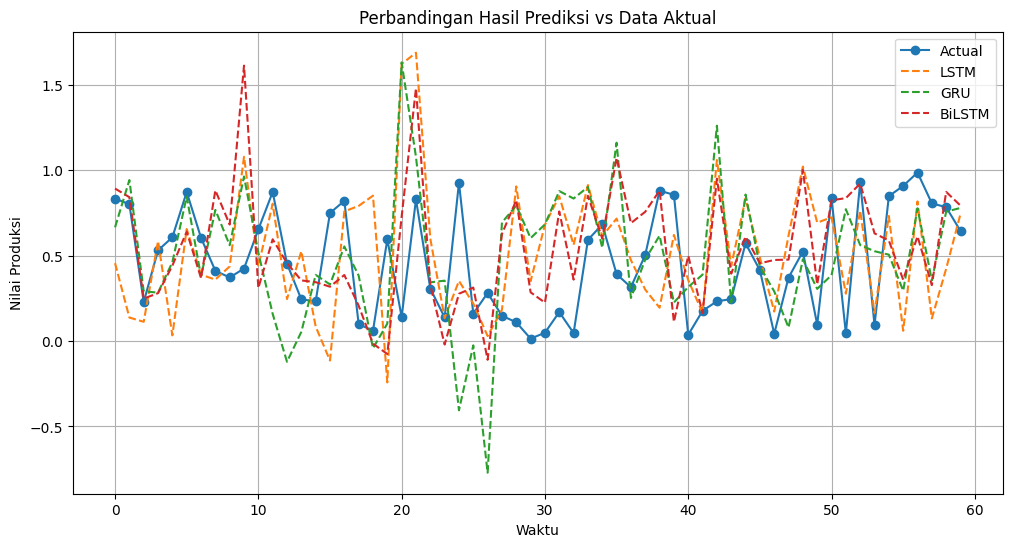

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.plot(actuals, label='Actual', marker='o')
plt.plot(lstm_pred, label='LSTM', linestyle='--')
plt.plot(gru_pred, label='GRU', linestyle='--')
plt.plot(bilstm_pred, label='BiLSTM', linestyle='--')

plt.title('Perbandingan Hasil Prediksi vs Data Aktual')
plt.xlabel('Waktu')
plt.ylabel('Nilai Produksi')
plt.legend()
plt.grid()

plt.show()

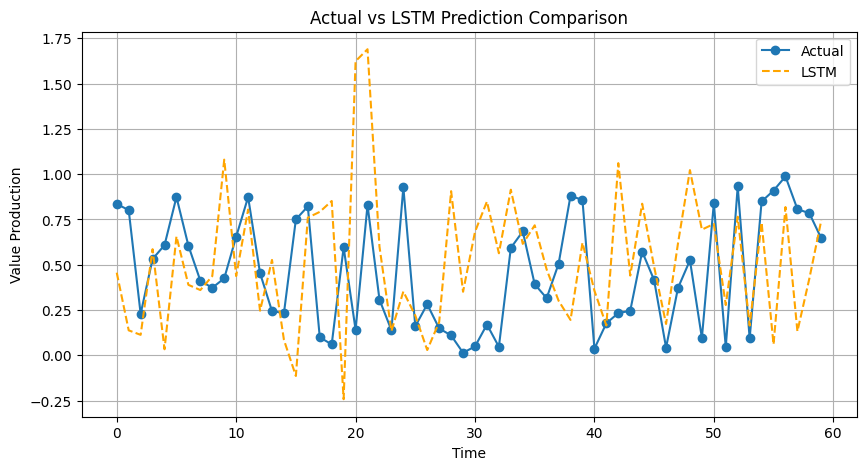

In [31]:
plt.figure(figsize=(10,5))

plt.plot(actuals, label='Actual', marker='o')
plt.plot(lstm_pred, label='LSTM', linestyle='--', color='orange')

plt.title('Actual vs LSTM Prediction Comparison')
plt.xlabel('Time')
plt.ylabel('Value Production')
plt.legend()
plt.grid()

plt.show()

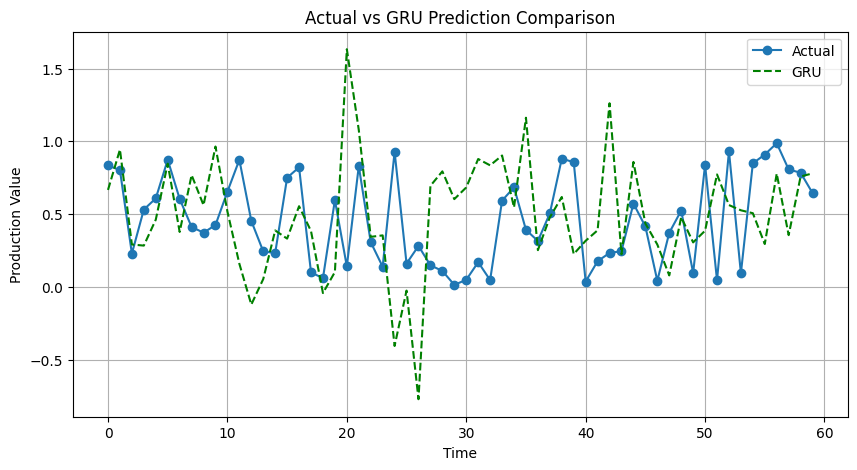

In [28]:
plt.figure(figsize=(10,5))

plt.plot(actuals, label='Actual', marker='o')
plt.plot(gru_pred, label='GRU', linestyle='--', color='green')

plt.title('Actual vs GRU Prediction Comparison')
plt.xlabel('Time')
plt.ylabel('Production Value')
plt.legend()
plt.grid()

plt.show()

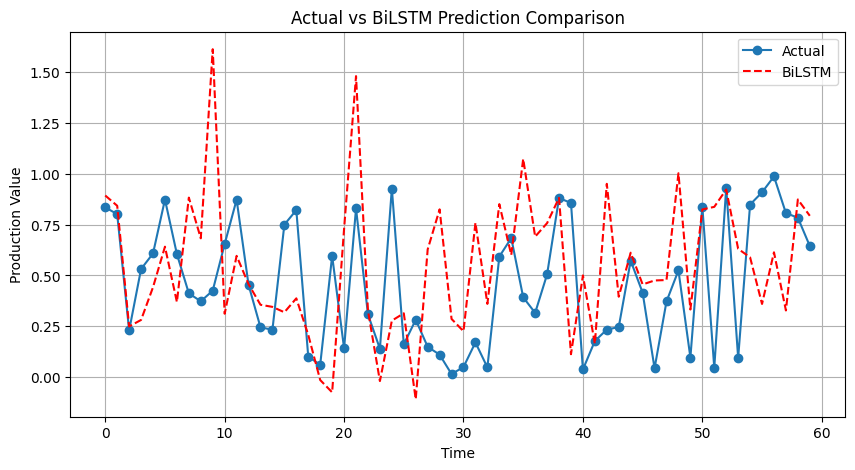

In [27]:
plt.figure(figsize=(10,5))

plt.plot(actuals, label='Actual', marker='o')
plt.plot(bilstm_pred, label='BiLSTM', linestyle='--', color='red')

plt.title('Actual vs BiLSTM Prediction Comparison')
plt.xlabel('Time')
plt.ylabel('Production Value')
plt.legend()
plt.grid()

plt.show()